# Credit Risk Analytics

**Data notice:** all records and target labels are synthetic. Results are for learning only and say nothing about real lending decisions.

Workflow: load data -> quick checks -> EDA -> encode + split + scale -> Logistic Regression and Decision Tree -> evaluate.

Run the cells from top to bottom.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42

## 1. Load the data

In [2]:
ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'data' / 'raw' / 'borrowers.csv'
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(2500, 13)


,borrower_id,age,annual_income,employment_years,credit_score,loan_amount,loan_term_months,interest_rate,existing_debt,debt_to_income_ratio,home_ownership,loan_purpose,default_flag
0,100001,25,173625,0.0,729,232994,60,12.36,16093,0.2537,MORTGAGE,MEDICAL,0
1,100002,59,319985,17.6,661,690774,48,15.82,156660,0.7486,OWN,EDUCATION,1
2,100003,53,259985,21.6,679,253678,48,12.71,13405,0.1686,RENT,BUSINESS,0
3,100004,42,210571,14.1,637,764261,24,13.18,67710,0.7571,MORTGAGE,EDUCATION,1
4,100005,42,349306,14.1,739,757419,48,13.10,50502,0.4048,RENT,DEBT_CONSOLIDATION,0


## 2. Quick data checks

In [3]:
df.info()
print()
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate borrower_id:', int(df['borrower_id'].duplicated().sum()))
print('Synthetic default rate:', round(df['default_flag'].mean(), 3))
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   borrower_id           2500 non-null   int64  
 1   age                   2500 non-null   int64  
 2   annual_income         2500 non-null   int64  
 3   employment_years      2500 non-null   float64
 4   credit_score          2500 non-null   int64  
 5   loan_amount           2500 non-null   int64  
 6   loan_term_months      2500 non-null   int64  
 7   interest_rate         2500 non-null   float64
 8   existing_debt         2500 non-null   int64  
 9   debt_to_income_ratio  2500 non-null   float64
 10  home_ownership        2500 non-null   str    
 11  loan_purpose          2500 non-null   str    
 12  default_flag          2500 non-null   int64  
dtypes: float64(3), int64(8), str(2)
memory usage: 254.0 KB

Missing values: 0
Duplicate borrower_id: 0
Synthetic default rate: 0.258


,count,mean,std,min,25%,50%,75%,max
borrower_id,2500.0,101250.50,721.83,100001.00,100625.75,101250.50,101875.25,102500.00
age,2500.0,45.41,14.42,21.00,33.00,45.00,58.00,70.00
annual_income,2500.0,693220.56,353349.70,142466.00,447417.75,623277.50,851713.00,2730405.00
employment_years,2500.0,14.05,8.98,0.00,6.68,13.90,21.00,40.40
credit_score,2500.0,679.95,63.78,451.00,639.00,678.00,722.25,850.00
loan_amount,2500.0,406414.19,249804.47,58156.00,238636.75,342040.50,506335.00,2000000.00
loan_term_months,2500.0,40.19,14.23,12.00,36.00,36.00,48.00,60.00
interest_rate,2500.0,13.03,2.25,5.89,11.47,12.97,14.50,21.47
existing_debt,2500.0,148153.68,118133.69,2392.00,63893.75,120192.50,196059.50,939962.00
debt_to_income_ratio,2500.0,0.30,0.14,0.02,0.19,0.29,0.39,1.03


## 3. Exploratory analysis

In [4]:
default_summary = df.groupby('default_flag').agg(
    borrowers=('borrower_id', 'count'),
    avg_credit_score=('credit_score', 'mean'),
    avg_dti=('debt_to_income_ratio', 'mean'),
    avg_loan_amount=('loan_amount', 'mean')
).round(2)
default_summary

,borrowers,avg_credit_score,avg_dti,avg_loan_amount
default_flag,,,,
0,1856,695.63,0.29,394689.09
1,644,634.75,0.34,440205.78


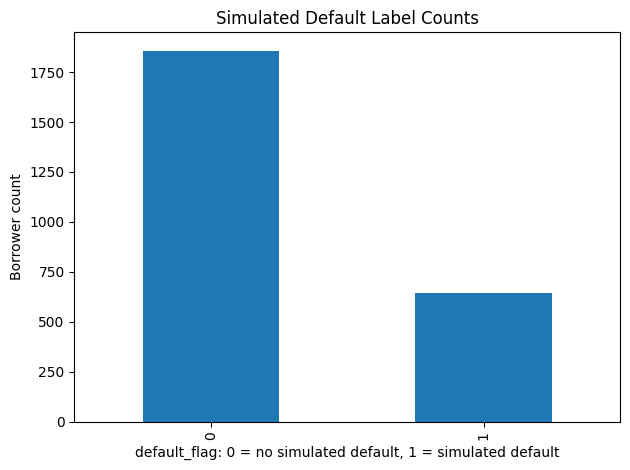

In [5]:
ax = df['default_flag'].value_counts().sort_index().plot(kind='bar', title='Simulated Default Label Counts')
ax.set_xlabel('default_flag: 0 = no simulated default, 1 = simulated default')
ax.set_ylabel('Borrower count')
plt.tight_layout()
plt.show()

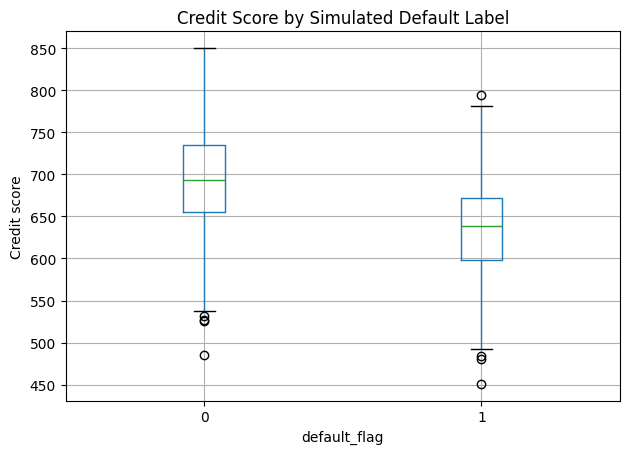

In [6]:
df.boxplot(column='credit_score', by='default_flag')
plt.suptitle('')
plt.title('Credit Score by Simulated Default Label')
plt.xlabel('default_flag')
plt.ylabel('Credit score')
plt.tight_layout()
plt.show()

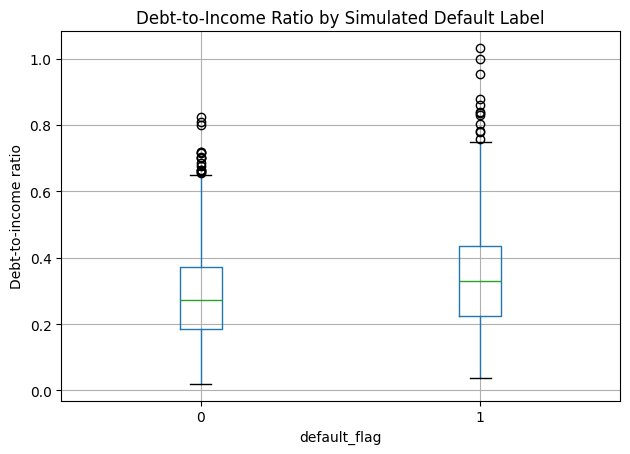

In [7]:
df.boxplot(column='debt_to_income_ratio', by='default_flag')
plt.suptitle('')
plt.title('Debt-to-Income Ratio by Simulated Default Label')
plt.xlabel('default_flag')
plt.ylabel('Debt-to-income ratio')
plt.tight_layout()
plt.show()

## 4. Prepare features

- Drop `borrower_id` (just an identifier) and the target.
- One-hot encode the two text columns (`home_ownership`, `loan_purpose`).
- Split into train and test **first** (stratified, so both keep the ~26% default rate).
- Scale numeric columns for Logistic Regression only. The scaler is fit on the **training set only**, then applied to the test set, so nothing from the test set leaks into training. Decision trees don't need scaling.

In [8]:
CATEGORICAL = ['home_ownership', 'loan_purpose']

X = df.drop(columns=['default_flag', 'borrower_id'])
y = df['default_flag']
numeric_cols = [c for c in X.columns if c not in CATEGORICAL]
X = pd.get_dummies(X, columns=CATEGORICAL, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler().fit(X_train[numeric_cols])
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Default rate  train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

Train: (1875, 17)  Test: (625, 17)
Default rate  train: 0.258  test: 0.258


## 5. Model 1: Logistic Regression

In [9]:
def evaluate(y_true, predictions, probabilities):
    return {
        'accuracy': accuracy_score(y_true, predictions),
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities),
        'confusion_matrix': confusion_matrix(y_true, predictions),
    }

def show(name, result):
    print(name)
    for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
        print(f'  {metric}: {result[metric]:.3f}')
    print('  Confusion matrix [[TN, FP], [FN, TP]]:')
    print(result['confusion_matrix'])

logreg = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)
logreg_proba = logreg.predict_proba(X_test_scaled)[:, 1]
logreg_result = evaluate(y_test, logreg.predict(X_test_scaled), logreg_proba)
show('Logistic Regression', logreg_result)

Logistic Regression
  accuracy: 0.712
  precision: 0.464
  recall: 0.770
  f1: 0.579
  roc_auc: 0.813
  Confusion matrix [[TN, FP], [FN, TP]]:
[[321 143]
 [ 37 124]]


## 6. Model 2: Decision Tree

A tree that is too deep memorises the training data. We pick `max_depth` using 5-fold cross-validation on the **training data only** (the test set stays untouched until the final evaluation).

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
depth_scores = {}
for depth in range(2, 9):
    candidate = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20,
                                       class_weight='balanced', random_state=RANDOM_STATE)
    depth_scores[depth] = cross_val_score(candidate, X_train, y_train, cv=cv, scoring='roc_auc').mean()

pd.Series(depth_scores, name='mean CV ROC-AUC').rename_axis('max_depth').round(3).to_frame()

,mean CV ROC-AUC
max_depth,
2,0.728
3,0.744
4,0.747
5,0.746
6,0.739
7,0.733
8,0.730


In [11]:
best_depth = max(depth_scores, key=depth_scores.get)
print('Chosen max_depth:', best_depth)

tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20,
                              class_weight='balanced', random_state=RANDOM_STATE)
tree.fit(X_train, y_train)
tree_proba = tree.predict_proba(X_test)[:, 1]
tree_result = evaluate(y_test, tree.predict(X_test), tree_proba)
show('Decision Tree', tree_result)

Chosen max_depth: 4
Decision Tree
  accuracy: 0.696
  precision: 0.447
  recall: 0.758
  f1: 0.562
  roc_auc: 0.768
  Confusion matrix [[TN, FP], [FN, TP]]:
[[313 151]
 [ 39 122]]


## 7. Compare the models

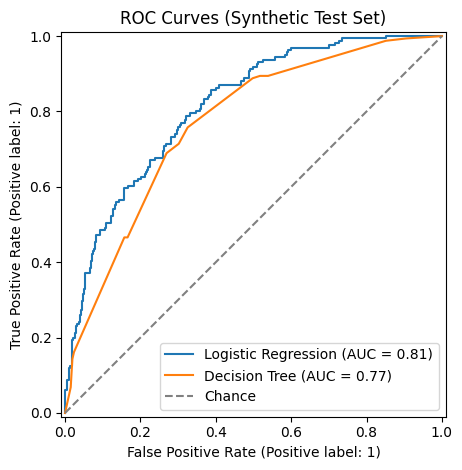

In [12]:
fig, ax = plt.subplots()
RocCurveDisplay.from_predictions(y_test, logreg_proba, name='Logistic Regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, tree_proba, name='Decision Tree', ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Chance')
ax.set_title('ROC Curves (Synthetic Test Set)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [13]:
comparison = pd.DataFrame({
    'Logistic Regression': {m: logreg_result[m] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']},
    'Decision Tree': {m: tree_result[m] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']},
}).round(3)
comparison

,Logistic Regression,Decision Tree
accuracy,0.712,0.696
precision,0.464,0.447
recall,0.770,0.758
f1,0.579,0.562
roc_auc,0.813,0.768


## 8. What does the tree look at?

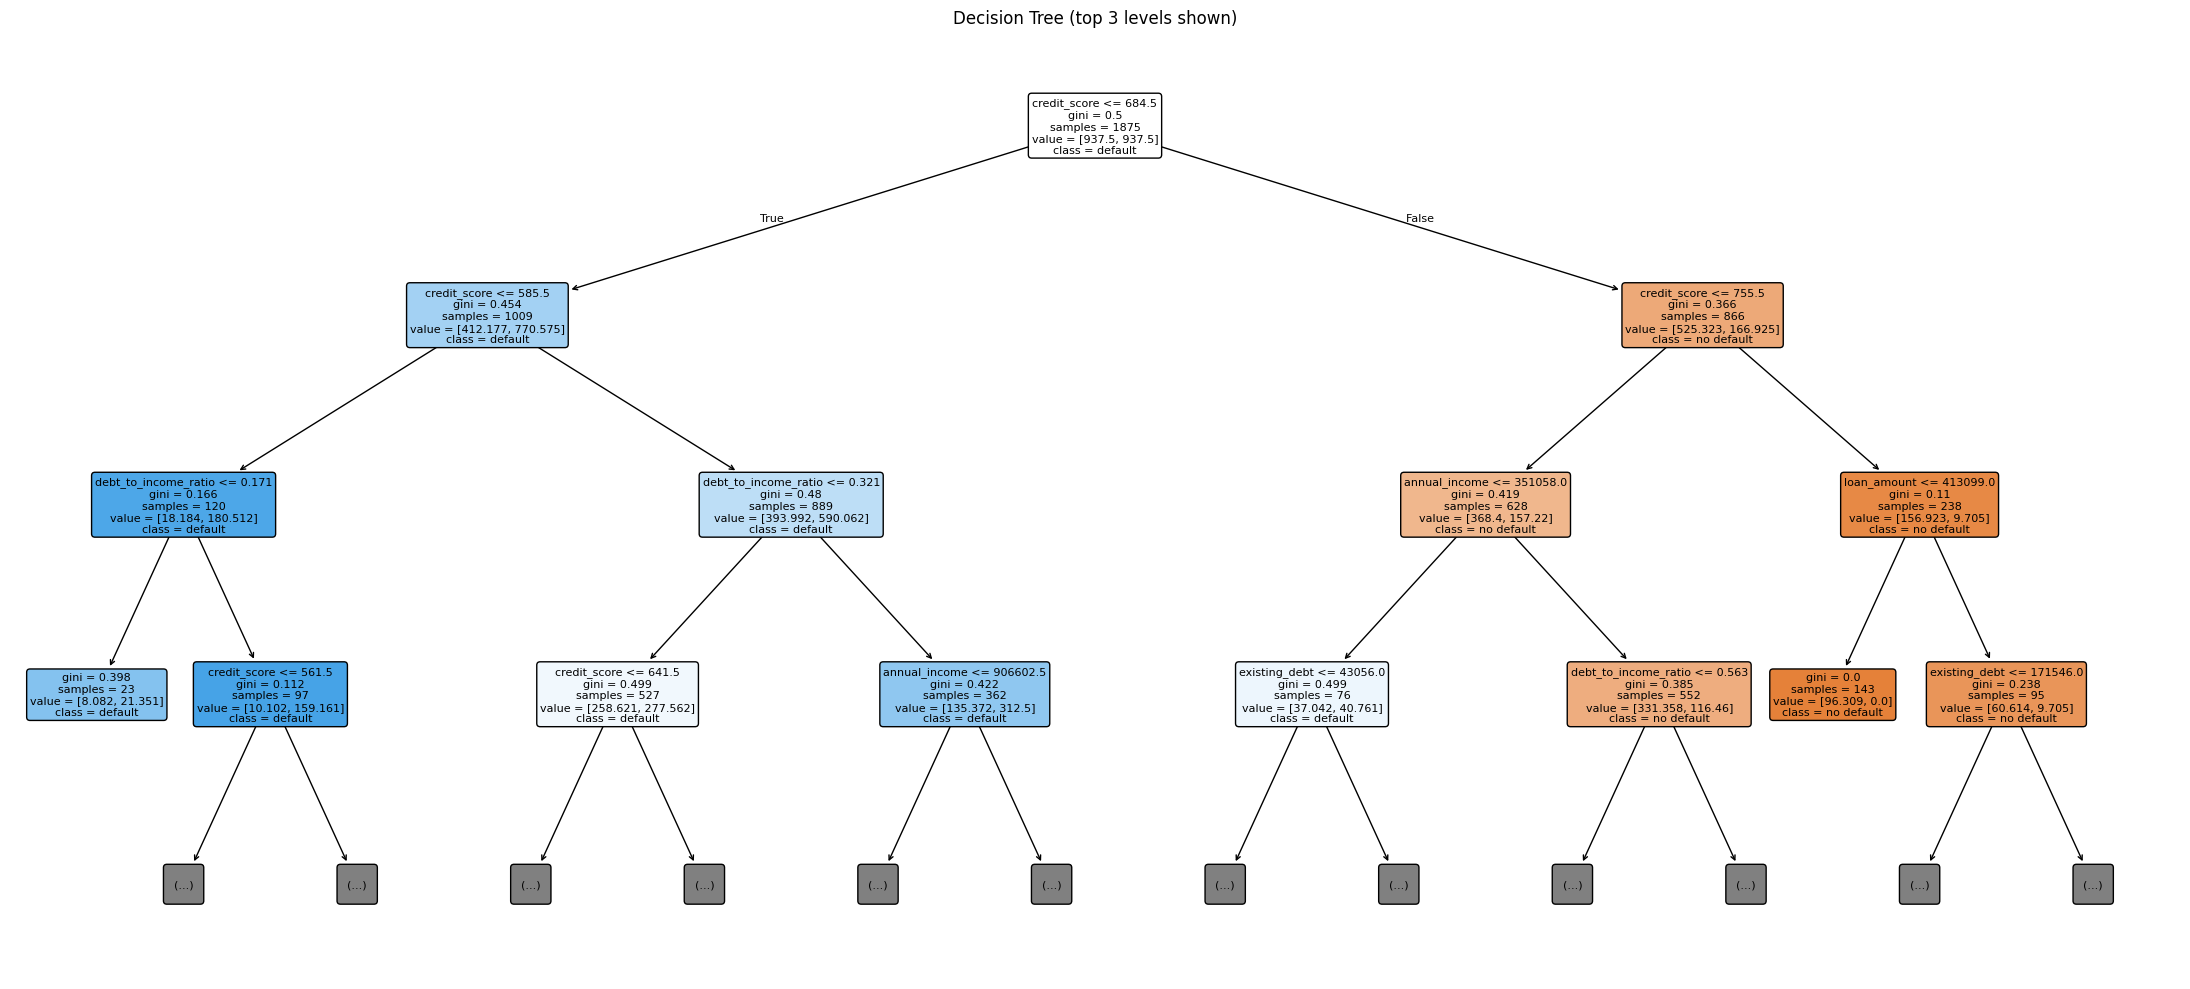

In [14]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(tree, feature_names=list(X.columns), class_names=['no default', 'default'],
          filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title('Decision Tree (top 3 levels shown)')
plt.tight_layout()
plt.show()

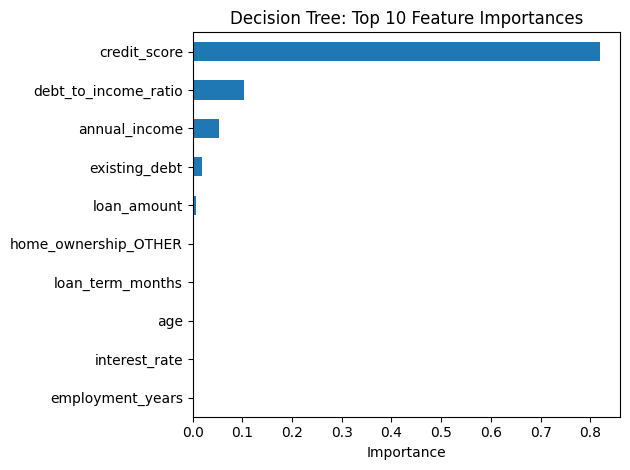

In [15]:
importances = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10).sort_values().plot(kind='barh', title='Decision Tree: Top 10 Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## Interpretation checklist

- Compare precision and recall, not accuracy alone. `class_weight='balanced'` trades precision for recall, so many non-defaulters get flagged.
- A false negative = a simulated default predicted as non-default; a false positive = a non-default flagged as default.
- The threshold stays at the default 0.5. In a real setting it should be chosen from business costs.
- The target is generated from a designed formula, so strong scores can reflect that construction and are not real-world predictive power.
- Real credit-risk work would add calibration, threshold/cost analysis, out-of-time validation, fairness review and independent data validation.